In [18]:
import sys 
sys.path.append("..")
import numpy as np 
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report

from src.data import load_clean
from src.split import scaffold_split
from src.features import morgan_fp, descriptors

df = load_clean()
tr, va, te = scaffold_split(df)
y = df["label"].values

X_fp = morgan_fp(df["mol"])
X_desc = descriptors(df["mol"])

feature_sets = {"fingerprint": X_fp, "descriptors": X_desc}

for fname, X in feature_sets.items():
    rf = RandomForestClassifier(n_estimators=500, class_weight="balanced",
                                random_state=42, n_jobs=-1)
    rf.fit(X[tr], y[tr])
    for split_name, idx in [("valid", va), ("test", te)]:
        p = rf.predict_proba(X[idx])[:, 1]
        print(f"RF | {fname} | {split_name} ROC-AUC: {roc_auc_score(y[idx], p):.3f}")
    print(classification_report(y[te], rf.predict(X[te]), digits=3))

Start: 2039 | removed conflicting-label rows: 22 | removed duplicates: 62 | final: 1955
RF | fingerprint | valid ROC-AUC: 0.947
RF | fingerprint | test ROC-AUC: 0.701
              precision    recall  f1-score   support

           0      0.704     0.209     0.322        91
           1      0.574     0.924     0.708       105

    accuracy                          0.592       196
   macro avg      0.639     0.566     0.515       196
weighted avg      0.634     0.592     0.529       196

RF | descriptors | valid ROC-AUC: 0.938
RF | descriptors | test ROC-AUC: 0.694
              precision    recall  f1-score   support

           0      0.677     0.231     0.344        91
           1      0.576     0.905     0.704       105

    accuracy                          0.592       196
   macro avg      0.627     0.568     0.524       196
weighted avg      0.623     0.592     0.537       196



In [19]:
from sklearn.model_selection import StratifiedGroupKFold 
from sklearn.pipeline import make_pipeline 
from sklearn.preprocessing import StandardScaler 

X_comb = np.hstack([X_fp, X_desc])
groups = df["scaffold"].astype("category").cat.codes.values 

models = {
    "RF": lambda: RandomForestClassifier(n_estimators=500, class_weight="balanced",
                                         random_state=42, n_jobs=-1),
    "LogReg": lambda: make_pipeline(StandardScaler(),
                                    LogisticRegression(max_iter=2000, class_weight="balanced")),
}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
for fname, X in {"fingerprint": X_fp, "descriptors": X_desc, "both": X_comb}.items():
    for mname, make in models.items():
        aucs = []
        for tr_i, te_i in cv.split(X, y, groups):
            m = make().fit(X[tr_i], y[tr_i])
            aucs.append(roc_auc_score(y[te_i], m.predict_proba(X[te_i])[:, 1]))
        print(f"{mname} | {fname}: {np.mean(aucs):.3f} ± {np.std(aucs):.3f}")

RF | fingerprint: 0.901 ± 0.021
LogReg | fingerprint: 0.851 ± 0.013
RF | descriptors: 0.869 ± 0.025
LogReg | descriptors: 0.841 ± 0.046
RF | both: 0.911 ± 0.024
LogReg | both: 0.857 ± 0.013


In [20]:
from sklearn.metrics import balanced_accuracy_score, recall_score

rf = RandomForestClassifier(n_estimators=500, class_weight="balanced",
                            random_state=42, n_jobs=-1).fit(X_desc[tr], y[tr])
p_va = rf.predict_proba(X_desc[va])[:, 1]
p_te = rf.predict_proba(X_desc[te])[:, 1]

thresholds = np.arange(0.3, 0.95, 0.05)
best_t = max(thresholds, key=lambda t: balanced_accuracy_score(y[va], p_va >= t))
print("Threshold chosen on valid:", round(best_t, 2))

for t in [0.5, best_t]:
    pred = (p_te >= t).astype(int)
    print(f"t={t:.2f} | test balanced acc: {balanced_accuracy_score(y[te], pred):.3f} "
          f"| recall class 0: {recall_score(y[te], pred, pos_label=0):.3f} "
          f"| recall class 1: {recall_score(y[te], pred, pos_label=1):.3f}")

Threshold chosen on valid: 0.6
t=0.50 | test balanced acc: 0.568 | recall class 0: 0.231 | recall class 1: 0.905
t=0.60 | test balanced acc: 0.607 | recall class 0: 0.319 | recall class 1: 0.895


In [21]:
from sklearn.model_selection import StratifiedKFold

def cv_auc(X, splitter, groups=None):
    aucs = []
    for tr_i, te_i in splitter.split(X, y, groups):
        m = RandomForestClassifier(n_estimators=500, class_weight="balanced",
                                   random_state=42, n_jobs=-1).fit(X[tr_i], y[tr_i])
        aucs.append(roc_auc_score(y[te_i], m.predict_proba(X[te_i])[:, 1]))
    return np.mean(aucs), np.std(aucs)

rand_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scaf_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

for fname, X in {"fingerprint": X_fp, "descriptors": X_desc, "both": X_comb}.items():
    r = cv_auc(X, rand_cv)
    s = cv_auc(X, scaf_cv, groups)
    print(f"{fname}: random {r[0]:.3f} ± {r[1]:.3f} | scaffold {s[0]:.3f} ± {s[1]:.3f}")

fingerprint: random 0.929 ± 0.013 | scaffold 0.901 ± 0.021
descriptors: random 0.894 ± 0.013 | scaffold 0.869 ± 0.025
both: random 0.938 ± 0.013 | scaffold 0.911 ± 0.024


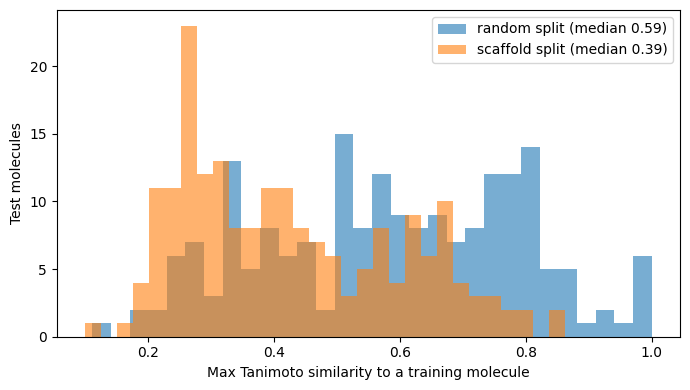

In [22]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

def max_sim(A, B):
    A = A.astype(np.float32)
    B = B.astype(np.float32)
    inter = A @ B.T
    union = A.sum(1)[:, None] + B.sum(1)[None, :] - inter
    return (inter / union).max(axis=1)

idx = np.arange(len(df))
r_tr, r_te = train_test_split(idx, test_size=0.1, stratify=y, random_state=42)

sim_random = max_sim(X_fp[r_te], X_fp[r_tr])
sim_scaffold = max_sim(X_fp[te], X_fp[tr])

plt.figure(figsize=(7, 4))
plt.hist(sim_random, bins=30, alpha=0.6,
         label=f"random split (median {np.median(sim_random):.2f})")
plt.hist(sim_scaffold, bins=30, alpha=0.6,
         label=f"scaffold split (median {np.median(sim_scaffold):.2f})")
plt.xlabel("Max Tanimoto similarity to a training molecule")
plt.ylabel("Test molecules")
plt.legend()
plt.tight_layout()
plt.savefig("../results/similarity_random_vs_scaffold.png", dpi=200)
plt.show()

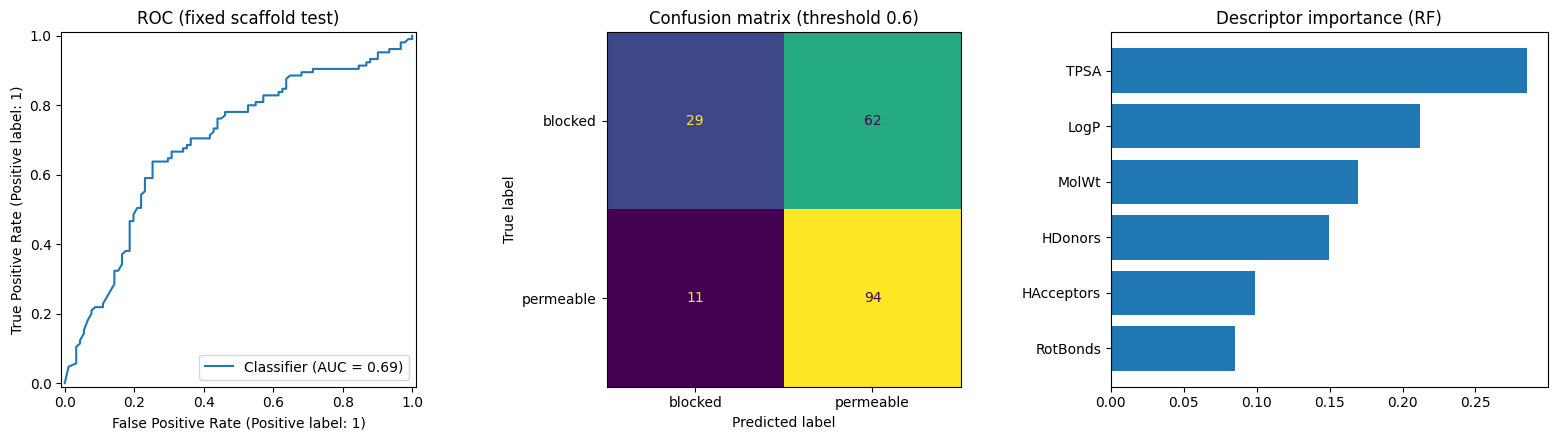

In [23]:
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay
from src.features import DESC_NAMES

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

RocCurveDisplay.from_predictions(y[te], p_te, ax=ax[0])
ax[0].set_title("ROC (fixed scaffold test)")

ConfusionMatrixDisplay.from_predictions(
    y[te], (p_te >= 0.6).astype(int), display_labels=["blocked", "permeable"],
    ax=ax[1], colorbar=False)
ax[1].set_title("Confusion matrix (threshold 0.6)")

order = np.argsort(rf.feature_importances_)
ax[2].barh(np.array(DESC_NAMES)[order], rf.feature_importances_[order])
ax[2].set_title("Descriptor importance (RF)")

plt.tight_layout()
plt.savefig("../results/final_model_plots.png", dpi=200)
plt.show()

In [24]:
rf_b = RandomForestClassifier(n_estimators=500, class_weight="balanced",
                              random_state=42, n_jobs=-1).fit(X_comb[tr], y[tr])
p_b = rf_b.predict_proba(X_comb[te])[:, 1]
yt = y[te]

rng = np.random.default_rng(0)
boot = []
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    if len(set(yt[i])) == 2:
        boot.append(roc_auc_score(yt[i], p_b[i]))
print("Test AUC (both):", round(roc_auc_score(yt, p_b), 3),
      "| 95% CI:", np.percentile(boot, [2.5, 97.5]).round(3))

Test AUC (both): 0.751 | 95% CI: [0.68  0.815]


In [26]:
from rdkit import Chem

for name, s in [("caffeine", "CN1C=NC2=C1C(=O)N(C(=O)N2C)C"),
                ("dopamine", "NCCc1ccc(O)c(O)c1")]:
    can = Chem.MolToSmiles(Chem.MolFromSmiles(s))
    print(name, "in training data:", can in set(df["clean_smiles"]))

caffeine in training data: True
dopamine in training data: True


In [27]:
from rdkit import Chem

candidates = {
    "nicotine":      "CN1CCCC1c1cccnc1",
    "amphetamine":   "CC(N)Cc1ccccc1",
    "L-DOPA":        "NC(Cc1ccc(O)c(O)c1)C(=O)O",
    "penicillin G":  "CC1(C)SC2C(NC(=O)Cc3ccccc3)C(=O)N2C1C(=O)O",
    "atenolol":      "CC(C)NCC(O)COc1ccc(CC(N)=O)cc1",
    "metformin":     "CN(C)C(=N)NC(N)=N",
}

seen = set(df["clean_smiles"])
for name, s in candidates.items():
    can = Chem.MolToSmiles(Chem.MolFromSmiles(s))
    print(f"{name}: in training data = {can in seen}")

nicotine: in training data = False
amphetamine: in training data = True
L-DOPA: in training data = False
penicillin G: in training data = True
atenolol: in training data = True
metformin: in training data = False
